In [ ]:
import pandas as pd
import os
import glob # busca archivos con patrones usando comodines como en bash
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.
Path to dataset files: /kaggle/input/network-intrusion-dataset


## Dataset: CIC-IDS2017

El dataset CIC-IDS2017 (Canadian Institute for Cybersecurity) está dividido en **8 archivos CSV**, cada uno correspondiente a un día de la semana de captura de tráfico de red, generado con la herramienta CICFlowMeter a partir de capturas `.pcap`.

Cada archivo representa un escenario distinto de tráfico:

- **Monday** — tráfico completamente benigno (día de referencia, sin ataques)
- **Tuesday** — tráfico benigno + ataques de fuerza bruta (FTP-Patator, SSH-Patator)
- **Wednesday** — tráfico benigno + ataques DoS/DDoS (Hulk, GoldenEye, Slowloris, Slowhttptest) y Heartbleed
- **Thursday** — tráfico benigno + ataques web (SQL Injection, XSS, Brute Force) e infiltración
- **Friday** — tráfico benigno + Botnet, PortScan y DDoS (LOIT)

Se concatenaron los 8 archivos en un único dataframe porque, para entrenar un modelo de clasificación **multiclase**, se necesita tener representados todos los tipos de ataque (y el tráfico benigno) en un mismo conjunto de datos. Cada fila del dataframe resultante es un **flujo de red** (no un paquete individual), caracterizado por ~78 features estadísticas (duración, bytes por segundo, flags TCP, etc.) más una columna `Label` que indica si es tráfico benigno o el tipo de ataque específico.

Esta unificación es el punto de partida para el resto del proyecto: EDA, limpieza, y entrenamiento de los modelos base (Random Forest, XGBoost, MLP).

In [ ]:
print(os.listdir(path))
csv_files = glob.glob(os.path.join(path, "*.csv"))

dfs = [pd.read_csv(f) for f in csv_files]

# verificar que todos tengan las mismas columnas (los nombres traen espacios al inicio)
for i, d in enumerate(dfs):
    d.columns = d.columns.str.strip()
    print(i, d.shape, "Mismas columnas?:", set(d.columns) == set(dfs[0].columns))

# concatenar los 8 csv's
df = pd.concat(dfs, ignore_index=True)
del dfs  # liberar memoria
print("Dataset completo:", df.shape)

['Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv']
0 (286467, 79) Mismas columnas?: True
1 (170366, 79) Mismas columnas?: True
2 (445909, 79) Mismas columnas?: True
3 (225745, 79) Mismas columnas?: True
4 (529918, 79) Mismas columnas?: True
5 (191033, 79) Mismas columnas?: True
6 (288602, 79) Mismas columnas?: True
7 (692703, 79) Mismas columnas?: True
Dataset completo: (2830743, 79)


In [ ]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
print(df.columns)
df.isna().sum() # revisar valores nuloe

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

,0
Destination Port,0
Flow Duration,0
Total Fwd Packets,0
Total Backward Packets,0
Total Length of Fwd Packets,0
...,...
Idle Mean,0
Idle Std,0
Idle Max,0
Idle Min,0


## Calidad de datos: NaN e infinitos

`isna()` no detecta los **infinitos** (`inf`). En CIC-IDS2017 aparecen en columnas de tasa como `Flow Bytes/s` y `Flow Packets/s` porque se calculan dividiendo entre la duración del flujo, y cuando esta es 0 el resultado es `inf` o `NaN`.

Estrategia: convertir `inf` a `NaN`, revisar **qué clases** tienen filas afectadas y, como son una fracción mínima del total, eliminarlas. Los outliers "reales" (valores enormes pero finitos) **no** se tocan: en este dataset suelen ser los propios ataques.

In [ ]:
num_cols = df.select_dtypes(include='number').columns

n_inf = np.isinf(df[num_cols]).sum()
n_nan = df[num_cols].isna().sum()
print("Infinitos por columna (solo las que tienen):")
print(n_inf[n_inf > 0])
print("\nNaN por columna (solo las que tienen):")
print(n_nan[n_nan > 0])

df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
filas_malas = df[num_cols].isna().any(axis=1)
print(f"\nFilas con NaN/inf: {filas_malas.sum()} ({filas_malas.mean() * 100:.3f}% del total)")
print("\nClases afectadas:")
print(df.loc[filas_malas, 'Label'].value_counts())

df = df.loc[~filas_malas].reset_index(drop=True)
print("\nShape despues de la limpieza:", df.shape)

Infinitos por columna (solo las que tienen):
Flow Bytes/s      1509
Flow Packets/s    2867
dtype: int64

NaN por columna (solo las que tienen):
Flow Bytes/s    1358
dtype: int64

Filas con NaN/inf: 2867 (0.101% del total)

Clases afectadas:
Label
BENIGN         1777
DoS Hulk        949
PortScan        126
Bot              10
FTP-Patator       3
DDoS              2
Name: count, dtype: int64

Shape despues de la limpieza: (2827876, 79)


In [ ]:
pd.DataFrame({
    'conteo': df['Label'].value_counts(),
    'porcentaje': df['Label'].value_counts(normalize=True) * 100
})

,conteo,porcentaje
Label,,
BENIGN,2271320,80.318939
DoS Hulk,230124,8.137698
PortScan,158804,5.615663
DDoS,128025,4.527249
DoS GoldenEye,10293,0.363983
FTP-Patator,7935,0.280599
SSH-Patator,5897,0.208531
DoS slowloris,5796,0.204959
DoS Slowhttptest,5499,0.194457


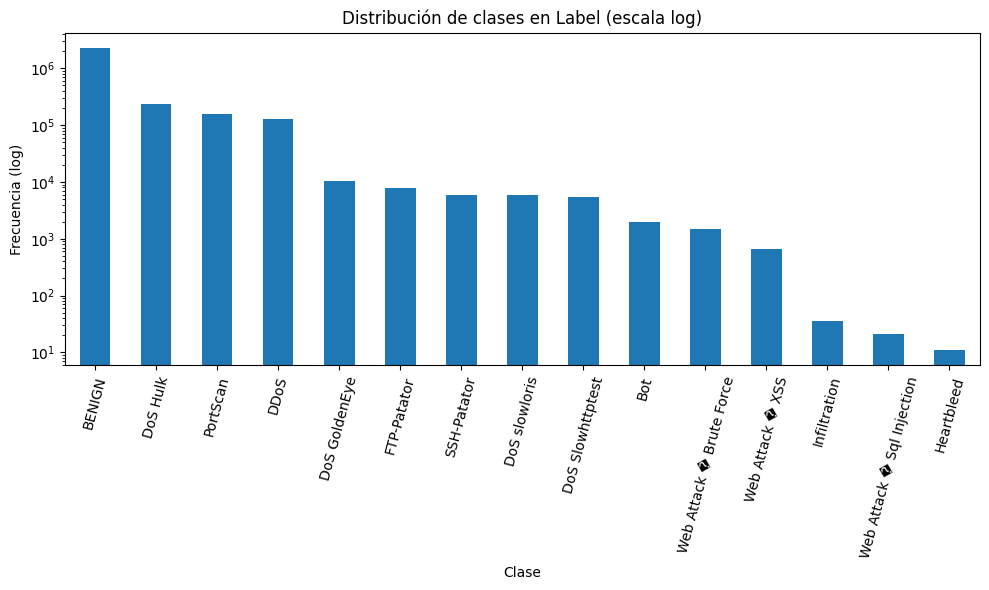

In [ ]:
conteo = df['Label'].value_counts()

plt.figure(figsize=(10, 6))
conteo.plot(kind='bar', logy=True)
plt.title('Distribución de clases en Label (escala log)')
plt.xlabel('Clase')
plt.ylabel('Frecuencia (log)')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
labels_unicos = df['Label'].unique()
mapa_labels = {label: i for i, label in enumerate(labels_unicos)}

df['Label_encoded'] = df['Label'].map(mapa_labels)

print(mapa_labels)  #para ver qué número corresponde a cada clase

{'BENIGN': 0, 'PortScan': 1, 'Web Attack � Brute Force': 2, 'Web Attack � XSS': 3, 'Web Attack � Sql Injection': 4, 'FTP-Patator': 5, 'SSH-Patator': 6, 'DDoS': 7, 'Bot': 8, 'Infiltration': 9, 'DoS slowloris': 10, 'DoS Slowhttptest': 11, 'DoS Hulk': 12, 'DoS GoldenEye': 13, 'Heartbleed': 14}


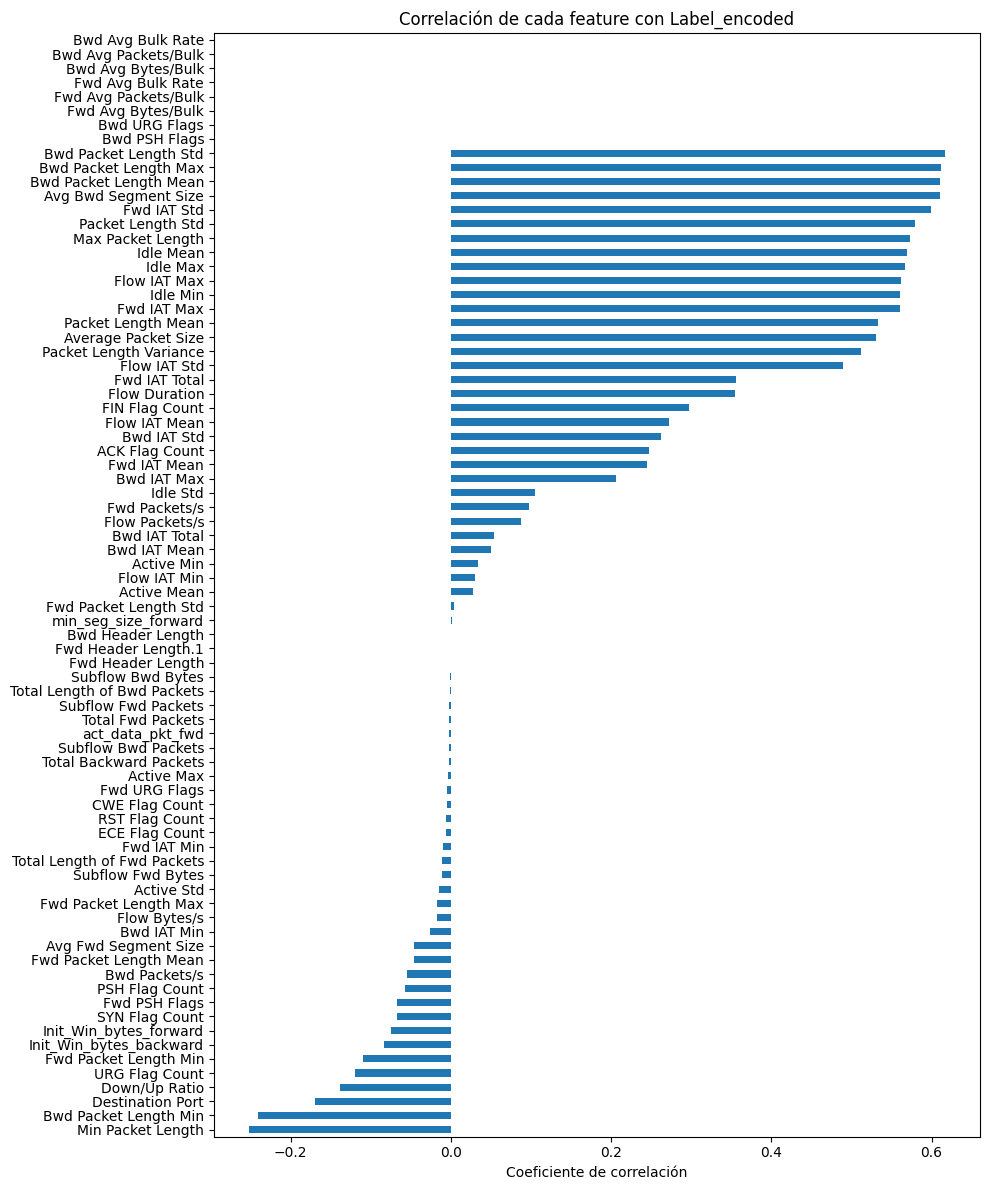

In [ ]:
# @title **CODE:** Grafico de barras para la correlacion completa
df_corr = df.select_dtypes(include='number').copy()
corr = df_corr.corr()
corr_target = corr['Label_encoded'].drop('Label_encoded').sort_values()
plt.figure(figsize=(10, 12))
corr_target.plot(kind='barh')
plt.title('Correlación de cada feature con Label_encoded')
plt.xlabel('Coeficiente de correlación')
plt.tight_layout()
plt.show()

In [ ]:
mask = (corr['Label_encoded'] > 0.5) | (corr['Label_encoded'] < -0.5)
columnas_relevantes = corr['Label_encoded'][mask].index #columnas con mayor correlacion con respecto a Label

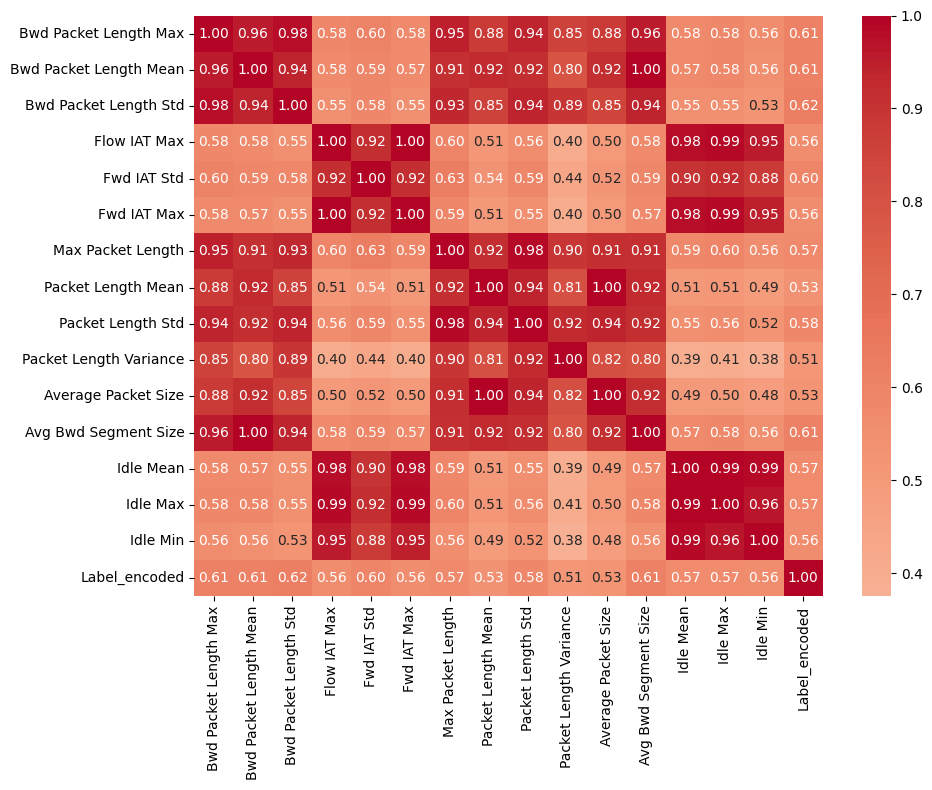

In [ ]:
# @title **CODE:** Correlacion de prueba para datos redundantes
corr_reducida = corr.loc[columnas_relevantes, columnas_relevantes]
plt.figure(figsize=(10, 8))
sns.heatmap(corr_reducida, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.tight_layout()
plt.show()

In [ ]:
df = df.drop(columns=['Avg Bwd Segment Size', 'Average Packet Size'], errors='ignore')
df = df.drop(columns=['Fwd IAT Max', 'Idle Max', 'Idle Min'], errors='ignore')
df = df.drop(columns=['Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std'], errors='ignore')
#limpieza de caracteristicas

In [ ]:
columnas_relevantes = columnas_relevantes.drop(['Avg Bwd Segment Size','Label_encoded', 'Average Packet Size', 'Fwd IAT Max', 'Idle Max', 'Idle Min', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std'], errors='ignore')
print(columnas_relevantes)

Index(['Bwd Packet Length Std', 'Flow IAT Max', 'Fwd IAT Std',
       'Packet Length Variance', 'Idle Mean'],
      dtype='object')


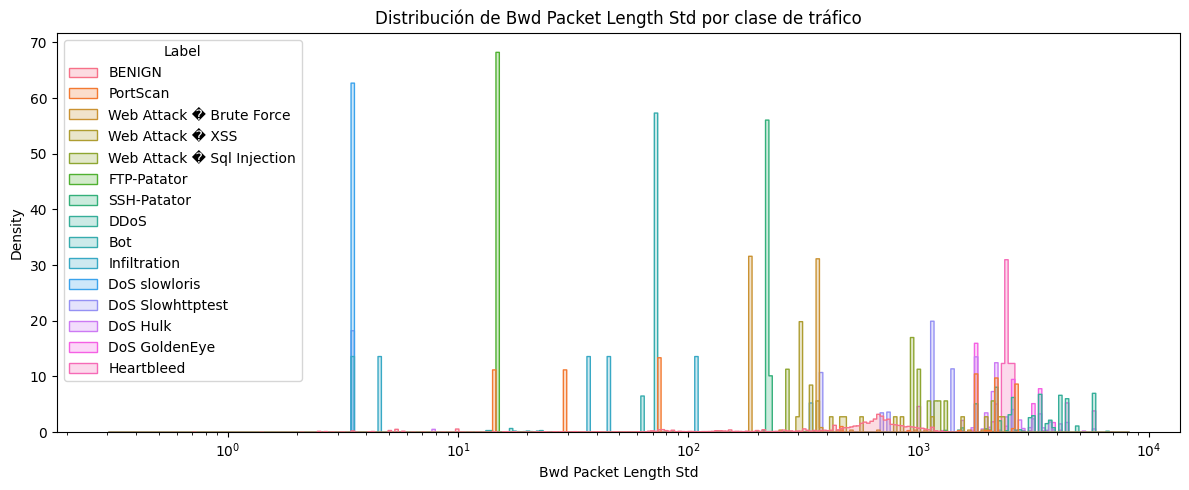

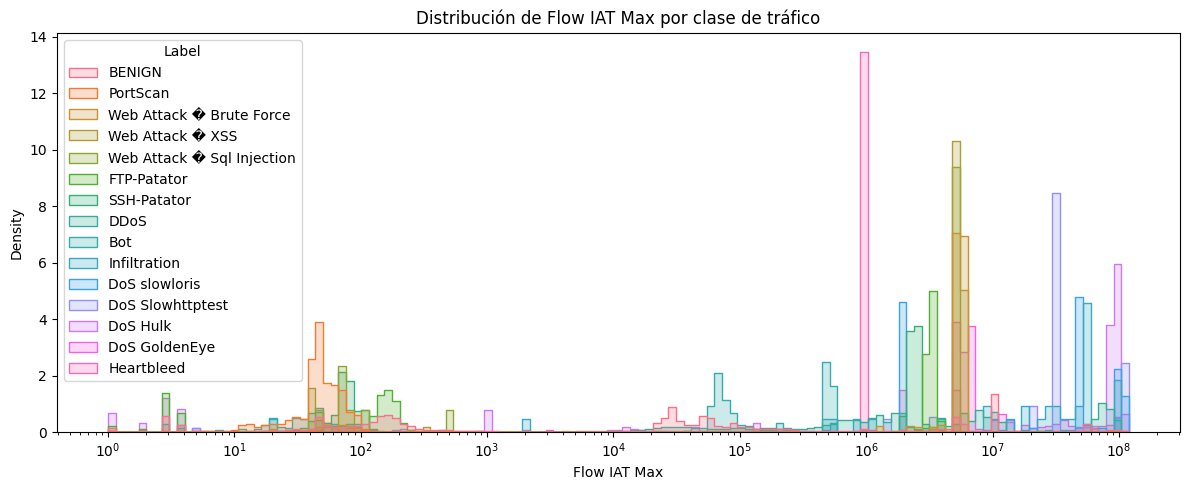

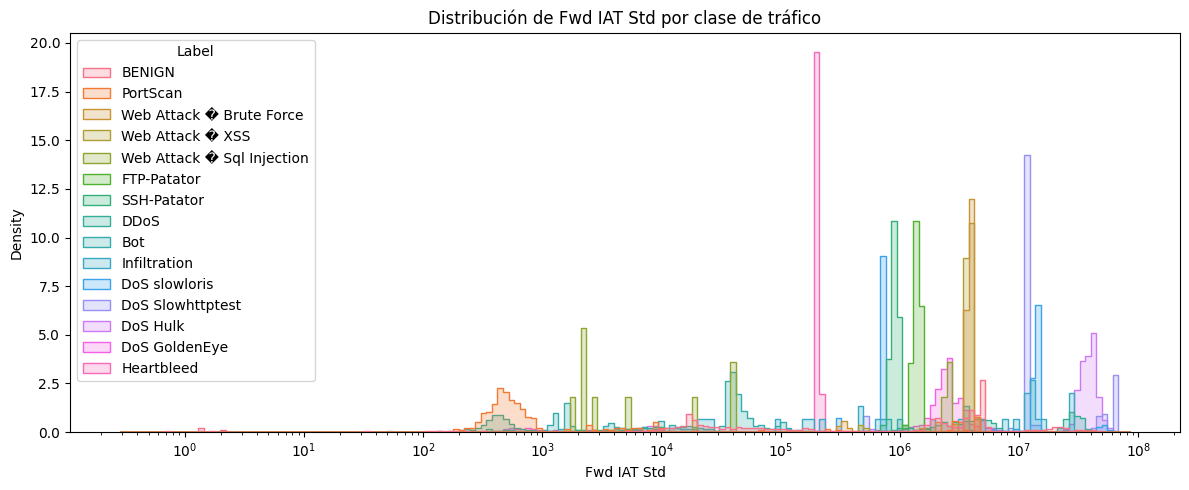

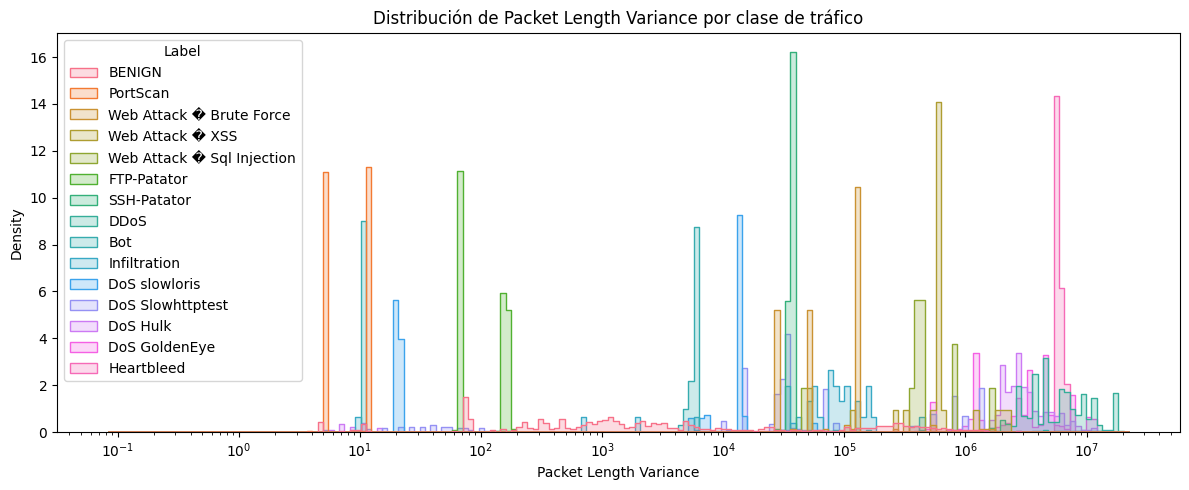

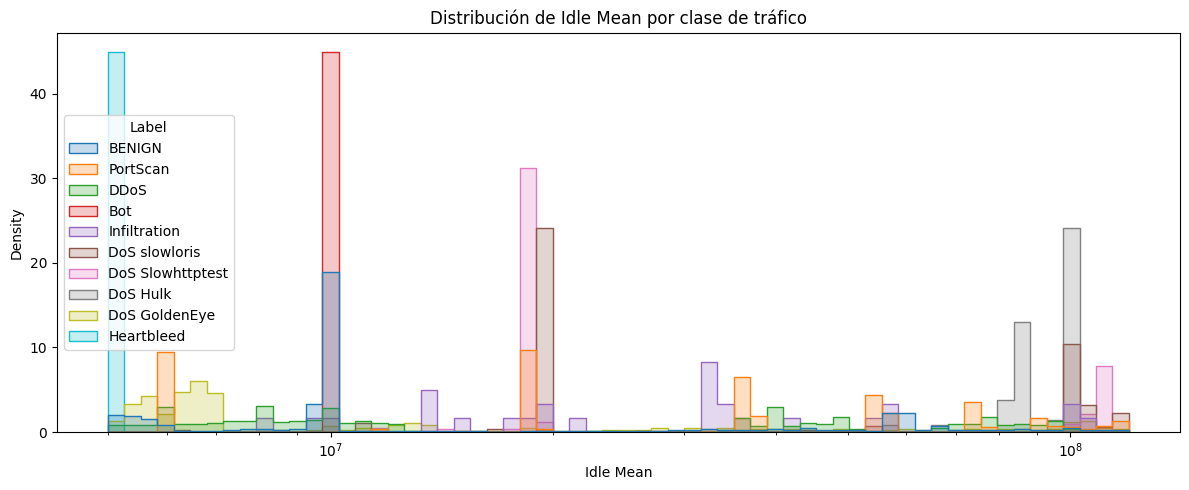

In [ ]:
for col in columnas_relevantes:
  plt.figure(figsize=(12, 5))

  #filtramos valores > 0 para poder usar log
  subset = df[df[col] > 0]

  sns.histplot(data=subset, x=col, hue='Label', log_scale=True,
                element='step', stat='density', common_norm=False)

  plt.title(f'Distribución de {col} por clase de tráfico')
  plt.tight_layout()
  plt.show()

In [ ]:
for col in columnas_relevantes:
    stats = df.groupby('Label')[col].agg( #agrupa las filas por clase de trafico
        mediana='median',
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    stats['IQR'] = stats['q3'] - stats['q1']

    print(f"\n=== {col} ===")
    print(stats)


=== Bwd Packet Length Std ===
                                mediana           q1           q3          IQR
Label                                                                         
BENIGN                         0.000000     0.000000     0.000000     0.000000
Bot                            0.000000     0.000000    72.231111    72.231111
DDoS                        2189.772933     0.000000  3346.363967  3346.363967
DoS GoldenEye               1762.500000     0.000000  3185.599598  3185.599598
DoS Hulk                    1895.881019     0.000000  2277.232520  2277.232520
DoS Slowhttptest               0.000000     0.000000     0.000000     0.000000
DoS slowloris                  0.000000     0.000000     3.464102     3.464102
FTP-Patator                   14.549750     0.000000    14.549750    14.549750
Heartbleed                  2374.669707  2364.989694  2451.401636    86.411942
Infiltration                   0.000000     0.000000     0.000000     0.000000
PortScan             

## Variable objetivo: binaria y multiclase

El proyecto se plantea en dos tareas sobre las mismas filas:

- **Binaria** (`Label_bin`): BENIGN (0) vs. ATAQUE (1).
- **Multiclase** (`Label_multi`): las 15 etiquetas originales se **agrupan por familia de ataque**. Hay clases con apenas decenas de filas (Heartbleed, Infiltration, SQL Injection) y un modelo no puede aprender de forma fiable con tan pocos ejemplos; agrupar por familia (que ademas tiene sentido en seguridad) reduce el desbalance extremo.

| Familia | Etiquetas originales |
|---|---|
| BENIGN | BENIGN |
| DoS | DoS Hulk, GoldenEye, slowloris, Slowhttptest |
| DDoS | DDoS |
| PortScan | PortScan |
| Brute Force | FTP-Patator, SSH-Patator |
| Web Attack | Brute Force, XSS, SQL Injection (web) |
| Bot | Bot |
| Raras | Infiltration, Heartbleed |

In [ ]:
from sklearn.model_selection import train_test_split

df['Label_bin'] = (df['Label'] != 'BENIGN').astype(int)

def familia(etiqueta):
    if etiqueta == 'BENIGN':            return 'BENIGN'
    if etiqueta.startswith('DoS'):      return 'DoS'
    if etiqueta == 'DDoS':              return 'DDoS'
    if etiqueta == 'PortScan':          return 'PortScan'
    if etiqueta in ('FTP-Patator', 'SSH-Patator'): return 'Brute Force'
    if etiqueta.startswith('Web Attack'): return 'Web Attack'
    if etiqueta == 'Bot':               return 'Bot'
    return 'Raras'                      # Infiltration, Heartbleed

df['Label_multi'] = df['Label'].map(familia)

# id numerico por familia (mismo enfoque manual que Label_encoded)
nombres_clases = df['Label_multi'].value_counts().index.tolist()
mapa_multi = {c: i for i, c in enumerate(nombres_clases)}
df['Label_multi_id'] = df['Label_multi'].map(mapa_multi)

print(mapa_multi)
pd.DataFrame({'conteo': df['Label_multi'].value_counts(),
              'porcentaje': df['Label_multi'].value_counts(normalize=True) * 100}).round(3)

{'BENIGN': 0, 'DoS': 1, 'PortScan': 2, 'DDoS': 3, 'Brute Force': 4, 'Web Attack': 5, 'Bot': 6, 'Raras': 7}


,conteo,porcentaje
Label_multi,,
BENIGN,2271320,80.319
DoS,251712,8.901
PortScan,158804,5.616
DDoS,128025,4.527
Brute Force,13832,0.489
Web Attack,2180,0.077
Bot,1956,0.069
Raras,47,0.002


## Split train/test y seleccion de features (sin fuga de informacion)

Se hace **un solo split** estratificado por `Label_multi_id` (80/20) y las dos tareas (binaria y multiclase) comparten exactamente las mismas filas de train y de test.

La seleccion de features se calcula **solo con train**: si la correlacion se calculara con todo el dataset, informacion del test influiria en que columnas se eligen.

In [ ]:
SEED = 67

idx_tr, idx_te = train_test_split(df.index, test_size=0.2,
                                  stratify=df['Label_multi_id'], random_state=SEED)
train = df.loc[idx_tr]

# 1) correlacion de cada feature con Label_bin, calculada SOLO en train
cols_label = ['Label_bin', 'Label_encoded', 'Label_multi_id']
num_train = train.select_dtypes('number').drop(columns=cols_label, errors='ignore')
corr_bin = num_train.corrwith(train['Label_bin'])
cols_sel = corr_bin[corr_bin.abs() > 0.5].index.tolist()
if len(cols_sel) < 3:   # proteccion: si el umbral deja muy pocas, usar las 8 de mayor |r|
    cols_sel = corr_bin.abs().sort_values(ascending=False).index[:8].tolist()
print(f"{len(cols_sel)} features con |r| > 0.5 respecto a Label_bin:")
print(corr_bin[cols_sel].round(3).sort_values())

# 2) seguro anti-redundancia: si dos features tienen |r| > 0.95 entre si, se queda la primera
corr_cols = train[cols_sel].corr().abs()
a_eliminar = []
for i, c in enumerate(cols_sel):
    if c in a_eliminar:
        continue
    for c2 in cols_sel[i + 1:]:
        if c2 not in a_eliminar and corr_cols.loc[c, c2] > 0.95:
            a_eliminar.append(c2)
FEATURES = [c for c in cols_sel if c not in a_eliminar]
print("\nEliminadas por redundancia adicional:", a_eliminar)
print("FEATURES finales:", FEATURES)

# 3) matrices X / y (binario y multiclase comparten X)
X_train = train[FEATURES].values
y_train_bin = train['Label_bin'].values
y_train_multi = train['Label_multi_id'].values

X_test = df.loc[idx_te, FEATURES].values
y_test_bin = df.loc[idx_te, 'Label_bin'].values
y_test_multi = df.loc[idx_te, 'Label_multi_id'].values

print("\nTrain:", X_train.shape, " Test:", X_test.shape)

8 features con |r| > 0.5 respecto a Label_bin:
Min Packet Length        -0.304
Bwd Packet Length Min    -0.282
Flow IAT Std              0.337
Flow IAT Max              0.389
Idle Mean                 0.391
Fwd IAT Std               0.423
Packet Length Variance    0.455
Bwd Packet Length Std     0.511
dtype: float64

Eliminadas por redundancia adicional: ['Flow IAT Max']
FEATURES finales: ['Bwd Packet Length Std', 'Packet Length Variance', 'Fwd IAT Std', 'Idle Mean', 'Flow IAT Std', 'Min Packet Length', 'Bwd Packet Length Min']

Train: (2262300, 7)  Test: (565576, 7)


## Por que se usan las caracteristicas seleccionadas

1. **Relacion con el objetivo:** solo se conservan las columnas con |correlacion| > 0.5 con `Label_bin`, calculada en train.
2. **Sin redundancia:** se eliminaron las columnas casi identicas entre si (r ~ 1.00 en el heatmap, p. ej. `Bwd Packet Length Mean` y `Avg Bwd Segment Size`) porque no aportan informacion nueva, cuestan computo y reparten artificialmente la importancia.
3. **Evidencia en distribuciones:** los histogramas por clase en escala log muestran picos separados (multimodalidad), senal de que las features diferencian tipos de trafico.
4. **Prueba empirica (celda siguiente):** se compara el mismo Random Forest con *todas* las columnas numericas vs. solo con las seleccionadas. Si el F1 es parecido, la reduccion de dimensionalidad esta justificada: mismo desempeno con menos columnas.

In [ ]:
# Funcion auxiliar: submuestra estratificada que conserva un minimo de filas por clase
def indices_estratificados(y, n, minimo_por_clase=0, seed=SEED):
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    clases, conteos = np.unique(y, return_counts=True)
    cuota = np.round(conteos / conteos.sum() * n).astype(int)
    cuota = np.maximum(cuota, np.minimum(minimo_por_clase, conteos))
    cuota = np.minimum(cuota, conteos)
    idx = [rng.choice(np.where(y == c)[0], size=q, replace=False) for c, q in zip(clases, cuota)]
    idx = np.concatenate(idx)
    rng.shuffle(idx)
    return idx

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

todas = num_train.columns.tolist()
sub = train.iloc[indices_estratificados(y_train_multi, 100_000, 200)]
ytmp = sub['Label_bin'].values
itr, iva = train_test_split(np.arange(len(sub)), test_size=0.3, stratify=ytmp, random_state=SEED)

filas = []
for nombre, columnas in [(f'Todas ({len(todas)} columnas)', todas),
                         (f'Seleccionadas ({len(FEATURES)} columnas)', FEATURES)]:
    Xs = sub[columnas].values
    t0 = time.perf_counter()
    rf_tmp = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED,
                                    class_weight='balanced').fit(Xs[itr], ytmp[itr])
    pred = rf_tmp.predict(Xs[iva])
    filas.append({'Conjunto de features': nombre,
                  'F1 (ataque)': f1_score(ytmp[iva], pred),
                  'F1 macro': f1_score(ytmp[iva], pred, average='macro'),
                  'Tiempo fit (s)': time.perf_counter() - t0})
pd.DataFrame(filas).round(4)

,Conjunto de features,F1 (ataque),F1 macro,Tiempo fit (s)
0,Todas (68 columnas),0.9925,0.9953,14.9857
1,Seleccionadas (7 columnas),0.8227,0.8839,6.3438


## Por que se hace un escalado

Las features tienen **escalas muy distintas** (p. ej. `Idle Mean` llega a 10^8 mientras otras variables estan en el rango de cientos) y colas muy largas.

- **SVM, Naive Bayes y redes neuronales** dependen de distancias o de supuestos sobre la forma de la distribucion: una variable con valores enormes domina a las demas si no se escala.
- **Arboles y Random Forest** dividen por umbrales y *no* necesitan escalado; se les deja sin transformar.
- Se aplica primero una **transformacion logaritmica con signo** (`sign(x) * log1p(|x|)`) para reducir la asimetria, y luego `StandardScaler` (media 0, desviacion 1).
- Todo va dentro de un `make_pipeline`: el escalador se ajusta **solo con train** (y dentro de cada fold en la validacion cruzada), evitando data leakage.

In [ ]:
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import make_pipeline

def log_signed(X):
    X = np.asarray(X, dtype=float)
    return np.sign(X) * np.log1p(np.abs(X))

# asimetria (skewness) antes y despues de la transformacion
muestra = pd.DataFrame(X_train[indices_estratificados(y_train_multi, 200_000, 200)], columns=FEATURES)
pd.DataFrame({'skew original': muestra.skew(),
              'skew tras log': pd.DataFrame(log_signed(muestra.values), columns=FEATURES).skew()}).round(2)

,skew original,skew tras log
Bwd Packet Length Std,3.41,1.15
Packet Length Variance,5.39,0.24
Fwd IAT Std,3.42,0.82
Idle Mean,3.06,1.52
Flow IAT Std,3.64,0.22
Min Packet Length,12.09,0.32
Bwd Packet Length Min,5.13,0.44


In [ ]:
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from scipy.stats import loguniform

def metric_row(name, y_true, y_pred, multiclase=False, **extra):
    """Fila de metricas. En multiclase precision/recall/F1 son macro (promedio por clase)."""
    avg = 'macro' if multiclase else 'binary'
    fila = {'Modelo': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, average=avg, zero_division=0),
            'Recall': recall_score(y_true, y_pred, average=avg, zero_division=0),
            'F1': f1_score(y_true, y_pred, average=avg, zero_division=0),
            'F1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0)}
    fila.update(extra)
    return fila

## Exploracion de hiperparametros (1): curvas de validacion

Se corrige la version anterior: ahora se mide en un **conjunto de validacion separado del train** (nunca el test), con **F1 macro** en lugar de accuracy, y se compara train vs. validacion para detectar sobreajuste. Se usa una submuestra de 150.000 filas para que corra rapido.

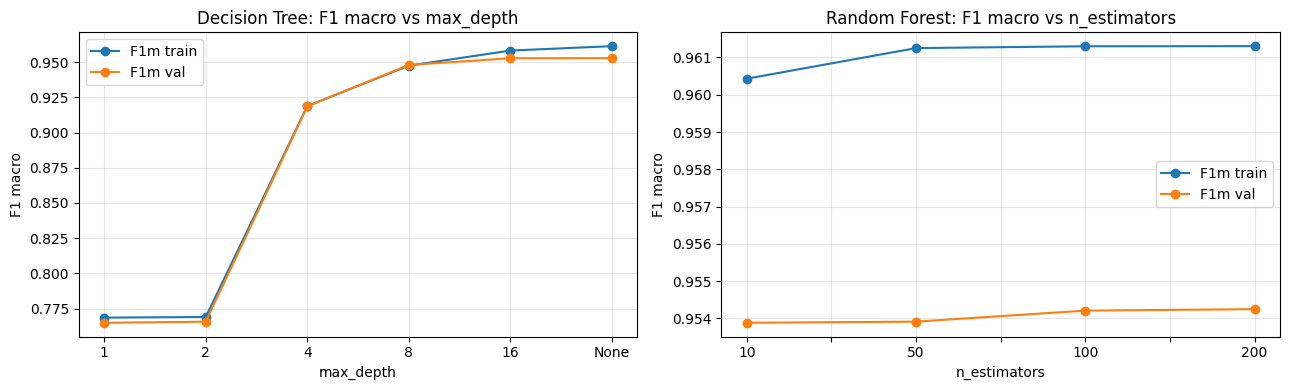

,F1m train,F1m val
max_depth,,
1,0.7686,0.7650
2,0.7690,0.7657
4,0.9188,0.9186
8,0.9475,0.9479
16,0.9582,0.9527
None,0.9613,0.9528


,F1m train,F1m val
n_estimators,,
10,0.9604,0.9539
50,0.9612,0.9539
100,0.9613,0.9542
200,0.9613,0.9542


In [ ]:
idx_v = indices_estratificados(y_train_multi, 150_000, 200)
Xv, yv = X_train[idx_v], y_train_bin[idx_v]
Xv_tr, Xv_val, yv_tr, yv_val = train_test_split(Xv, yv, test_size=0.3, stratify=yv, random_state=SEED)

def f1m(y, p):
    return f1_score(y, p, average='macro')


depths = [1, 2, 4, 8, 16, None]
res_dt = []
for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xv_tr, yv_tr)
    res_dt.append((str(d), f1m(yv_tr, dt.predict(Xv_tr)), f1m(yv_val, dt.predict(Xv_val))))
res_dt = pd.DataFrame(res_dt, columns=['max_depth', 'F1m train', 'F1m val']).set_index('max_depth')


n_trees = [10, 50, 100, 200]
res_rf = []
for n in n_trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1).fit(Xv_tr, yv_tr)
    res_rf.append((str(n), f1m(yv_tr, rf.predict(Xv_tr)), f1m(yv_val, rf.predict(Xv_val))))
res_rf = pd.DataFrame(res_rf, columns=['n_estimators', 'F1m train', 'F1m val']).set_index('n_estimators')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
res_dt.plot(marker='o', ax=axes[0], title='Decision Tree: F1 macro vs max_depth')
res_rf.plot(marker='o', ax=axes[1], title='Random Forest: F1 macro vs n_estimators')
for ax in axes:
    ax.set_ylabel('F1 macro')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(res_dt.round(4))
display(res_rf.round(4))

## Exploracion de hiperparametros (2): `RandomizedSearchCV`

Busqueda aleatoria con validacion cruzada estratificada de 3 folds y `scoring='f1_macro'`, sobre una **submuestra estratificada de 20.000 filas** del train (el SVM es cuadratico en el numero de filas, asi que no se puede entrenar con 2 millones). Todos los modelos usan la **misma submuestra**, por lo que su puntaje de CV es comparable y sirve para **elegir los 2 mejores sin tocar el test**.

Cada modelo recibe el preprocesamiento que necesita: GNB y SVM con transformacion log (y SVM ademas con `StandardScaler`); arboles sin transformar.

In [ ]:
SEARCH_N = 20_000
idx_s = indices_estratificados(y_train_multi, SEARCH_N, 200)
Xs, ys = X_train[idx_s], y_train_bin[idx_s]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# nombre: (modelo, espacio de busqueda, n_iter cantidad de iteraciones xd, n_jobs osea numero de nucleos que se usan en la busqueda)
busquedas = {
    'GNB': (make_pipeline(FunctionTransformer(log_signed), GaussianNB()),
            {'gaussiannb__var_smoothing': loguniform(1e-11, 1e-5)}, 6, 1),

    'DT': (DecisionTreeClassifier(random_state=SEED),
           {'criterion': ['gini', 'entropy'],
            'max_depth': [5, 10, 15, 20, 30, None],
            'min_samples_leaf': [1, 2, 5, 10, 20, 50],
            'class_weight': [None, 'balanced']}, 30, -1),

    'RF': (RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
           {'max_depth': [10, 20, 30, None],
            'min_samples_leaf': [1, 2, 5, 10],
            'max_features': ['sqrt', 'log2', 0.5],
            'class_weight': [None, 'balanced', 'balanced_subsample']}, 12, 1),   # el bosque ya usa todos los nucleos

    'SVM': (make_pipeline(FunctionTransformer(log_signed), StandardScaler(),
                          SVC(kernel='rbf', cache_size=500, random_state=SEED)),
            {'svc__C': loguniform(1e-1, 1e2),          # loguniform: explora ordenes de magnitud por igual
             'svc__gamma': loguniform(1e-3, 1e0),
             'svc__class_weight': [None, 'balanced']}, 8, -1),
}

busqueda_res = {}
for nombre, (modelo, espacio, n_iter, nj) in busquedas.items():
    t0 = time.perf_counter()
    b = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, cv=cv, scoring='f1_macro',
                           n_jobs=nj, random_state=SEED, refit=True)
    b.fit(Xs, ys)
    busqueda_res[nombre] = b
    print(f"{nombre}: F1 macro CV = {b.best_score_:.4f} | {time.perf_counter() - t0:.0f}s | {b.best_params_}")

GNB: F1 macro CV = 0.6094 | 0s | {'gaussiannb__var_smoothing': np.float64(1.8841200866151848e-08)}
DT: F1 macro CV = 0.9385 | 6s | {'min_samples_leaf': 2, 'max_depth': 10, 'criterion': 'entropy', 'class_weight': None}
RF: F1 macro CV = 0.9416 | 43s | {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30, 'class_weight': None}
SVM: F1 macro CV = 0.9330 | 153s | {'svc__C': np.float64(4.340645213116581), 'svc__class_weight': None, 'svc__gamma': np.float64(0.7145931229589184)}


## Modelos binarios (BENIGN vs. ATAQUE)

1. Se ordenan los 4 candidatos por su **F1 macro de CV** (calculado solo con train) y se **eligen los 2 mejores**.
2. Cada modelo se reentrena con sus mejores hiperparametros sobre **todo el train** (el SVM, sobre una submuestra estratificada de 40.000 filas) y se evalua **una sola vez** en el test.

In [ ]:
SVM_FIT_N = 40_000   # filas con las que se entrena el SVM final

def ajustar(nombre, estimador, X, y, y_strat):
    """Entrena una copia del estimador. El SVM usa submuestra estratificada; los demas todo el train."""
    est = clone(estimador)
    if nombre == 'SVM':
        i = indices_estratificados(y_strat, SVM_FIT_N, 300)
        est.fit(X[i], y[i])
    else:
        est.fit(X, y)
    return est

ranking_cv = pd.Series({n: b.best_score_ for n, b in busqueda_res.items()}).sort_values(ascending=False)
seleccionados = ranking_cv.index[:2].tolist()
print("Ranking por F1 macro (CV en train):")
print(ranking_cv.round(4))
print("\nModelos seleccionados para multiclase:", seleccionados)

filas_bin, modelos_bin, pred_bin = [], {}, {}
for nombre, b in busqueda_res.items():
    t0 = time.perf_counter()
    m = ajustar(nombre, b.best_estimator_, X_train, y_train_bin, y_train_multi)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = m.predict(X_test)
    t_pred = time.perf_counter() - t0
    modelos_bin[nombre], pred_bin[nombre] = m, pred
    filas_bin.append(metric_row(nombre, y_test_bin, pred, F1_CV=b.best_score_,
                                fit_s=t_fit, predict_s=t_pred))
    print(f"{nombre} listo (fit {t_fit:.0f}s, predict {t_pred:.0f}s)")

resultados_bin = pd.DataFrame(filas_bin).set_index('Modelo').sort_values('F1_macro', ascending=False)
display(resultados_bin.round(4))

Ranking por F1 macro (CV en train):
RF     0.9416
DT     0.9385
SVM    0.9330
GNB    0.6094
dtype: float64

Modelos seleccionados para multiclase: ['RF', 'DT']
GNB listo (fit 2s, predict 0s)
DT listo (fit 22s, predict 0s)
RF listo (fit 661s, predict 3s)
SVM listo (fit 12s, predict 140s)


,Accuracy,Precision,Recall,F1,F1_macro,F1_CV,fit_s,predict_s
Modelo,,,,,,,,
RF,0.9742,0.9872,0.8802,0.9306,0.9574,0.9416,661.4483,3.3551
DT,0.9730,0.9866,0.8749,0.9274,0.9554,0.9385,21.7561,0.0471
SVM,0.9619,0.9362,0.8653,0.8993,0.9379,0.9330,11.8602,140.3628
GNB,0.7011,0.3248,0.4807,0.3877,0.5950,0.6094,1.8899,0.2681


## Modelos multiclase (los 2 mejores)

Se toman los dos algoritmos elegidos en la fase binaria, con los **mismos hiperparametros**, y se entrenan sobre `Label_multi_id`. Para el SVM, la submuestra conserva al menos 300 filas por clase (si fuera proporcional, las clases raras casi no aparecerian). Las metricas de precision/recall/F1 son **macro**: promedian las clases sin ponderar por su tamano.

In [ ]:
filas_multi, modelos_multi, pred_multi = [], {}, {}
for nombre in seleccionados:
    t0 = time.perf_counter()
    m = ajustar(nombre, busqueda_res[nombre].best_estimator_, X_train, y_train_multi, y_train_multi)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = m.predict(X_test)
    t_pred = time.perf_counter() - t0
    modelos_multi[nombre], pred_multi[nombre] = m, pred
    filas_multi.append(metric_row(nombre, y_test_multi, pred, multiclase=True,
                                  fit_s=t_fit, predict_s=t_pred))
    print(f"{nombre} multiclase listo (fit {t_fit:.0f}s, predict {t_pred:.0f}s)")

resultados_multi = pd.DataFrame(filas_multi).set_index('Modelo').sort_values('F1_macro', ascending=False)
display(resultados_multi.round(4))

etiquetas = list(range(len(nombres_clases)))
for nombre in seleccionados:
    print(f"\n=== {nombre}: reporte por clase ===")
    print(classification_report(y_test_multi, pred_multi[nombre], labels=etiquetas,
                                target_names=nombres_clases, zero_division=0, digits=3))

RF multiclase listo (fit 672s, predict 6s)
DT multiclase listo (fit 19s, predict 0s)


,Accuracy,Precision,Recall,F1,F1_macro,fit_s,predict_s
Modelo,,,,,,,
RF,0.9739,0.9521,0.7123,0.7797,0.7797,671.8087,6.3246
DT,0.9701,0.7201,0.6404,0.6730,0.6730,19.4884,0.0712



=== RF: reporte por clase ===
              precision    recall  f1-score   support

      BENIGN      0.971     0.997     0.984    454265
         DoS      0.985     0.761     0.859     50343
    PortScan      0.987     0.999     0.993     31761
        DDoS      0.991     0.990     0.991     25605
 Brute Force      0.958     0.794     0.868      2766
  Web Attack      0.971     0.156     0.269       436
         Bot      0.753     0.445     0.559       391
       Raras      1.000     0.556     0.714         9

    accuracy                          0.974    565576
   macro avg      0.952     0.712     0.780    565576
weighted avg      0.974     0.974     0.972    565576


=== DT: reporte por clase ===
              precision    recall  f1-score   support

      BENIGN      0.971     0.996     0.983    454265
         DoS      0.956     0.744     0.837     50343
    PortScan      0.988     0.997     0.992     31761
        DDoS      0.962     0.961     0.962     25605
 Brute Force    

## Resultados

Las graficas usan **F1 macro** y matrices de confusion **normalizadas por fila** (cada fila suma 1 = recall de esa clase), porque con un dataset tan desbalanceado los conteos absolutos esconden los errores en las clases pequeas.

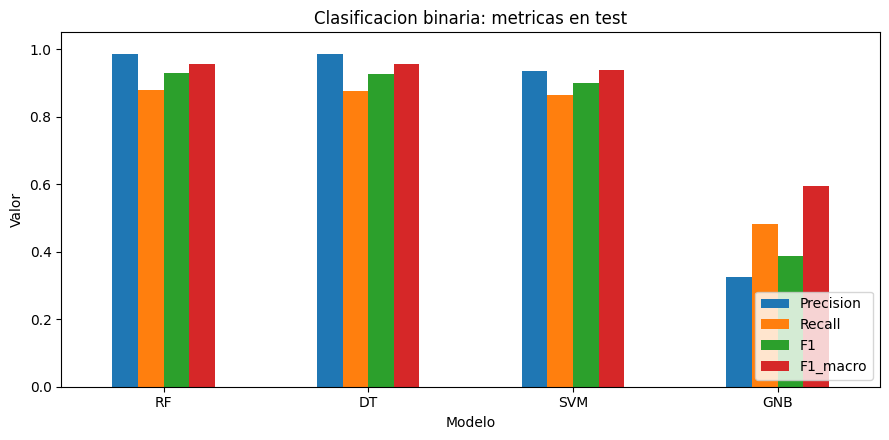

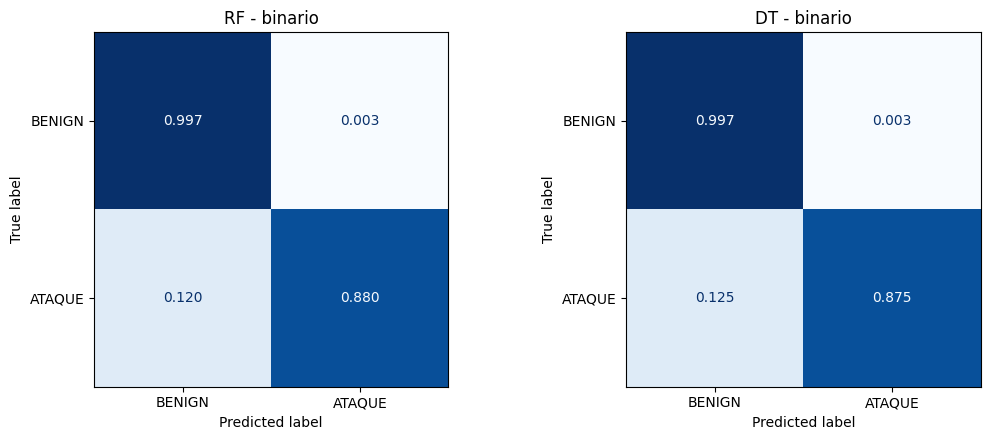

In [ ]:
# 1) Comparacion de los 4 candidatos en binario
fig, ax = plt.subplots(figsize=(9, 4.5))
resultados_bin[['Precision', 'Recall', 'F1', 'F1_macro']].plot(kind='bar', ax=ax)
ax.set_title('Clasificacion binaria: metricas en test')
ax.set_ylabel('Valor')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2) Matrices de confusion binarias de los 2 seleccionados
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nombre in zip(axes, seleccionados):
    ConfusionMatrixDisplay.from_predictions(y_test_bin, pred_bin[nombre], normalize='true',
                                            display_labels=['BENIGN', 'ATAQUE'], cmap='Blues',
                                            values_format='.3f', ax=ax, colorbar=False)
    ax.set_title(f'{nombre} - binario')
plt.tight_layout()
plt.show()

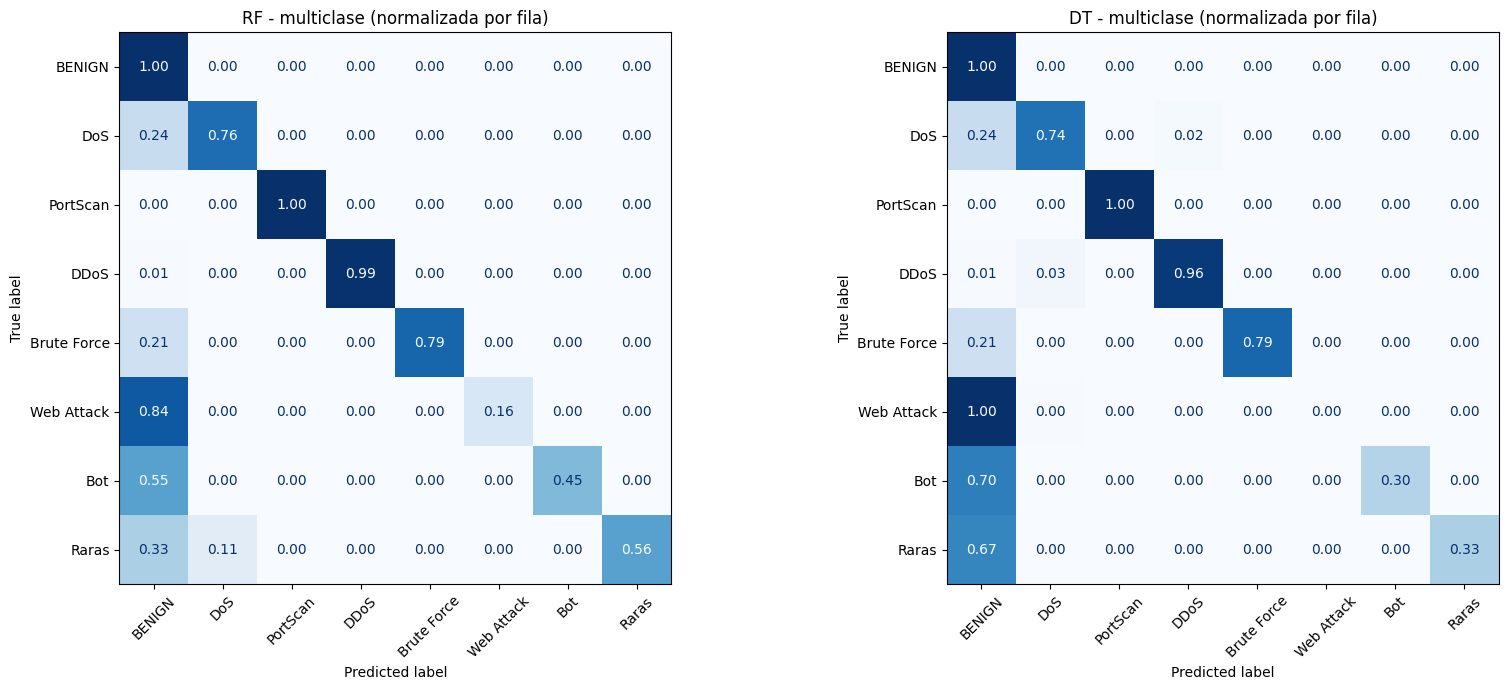

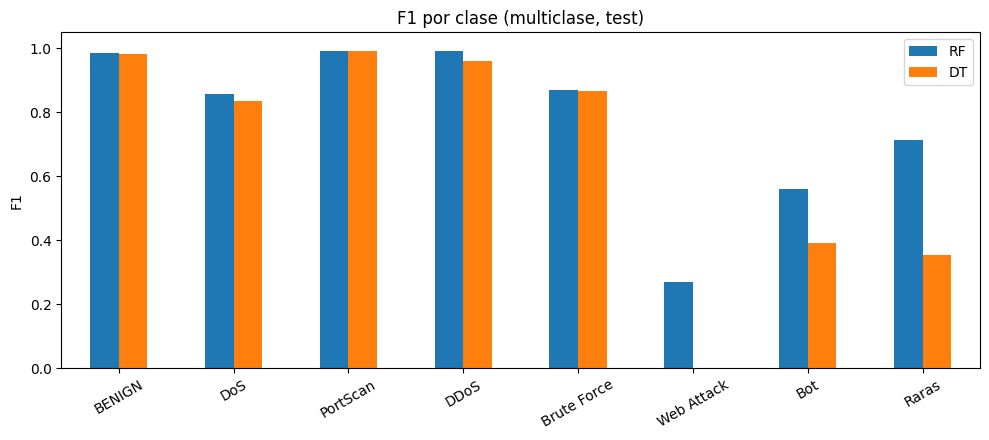

In [ ]:
# 3) Matrices de confusion multiclase de los 2 seleccionados
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, nombre in zip(axes, seleccionados):
    ConfusionMatrixDisplay.from_predictions(y_test_multi, pred_multi[nombre], labels=etiquetas,
                                            display_labels=nombres_clases, normalize='true',
                                            cmap='Blues', values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(f'{nombre} - multiclase (normalizada por fila)')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# 4) F1 por clase (multiclase)
f1_clase = pd.DataFrame({
    nombre: f1_score(y_test_multi, pred_multi[nombre], labels=etiquetas, average=None, zero_division=0)
    for nombre in seleccionados}, index=nombres_clases)
f1_clase.plot(kind='bar', figsize=(10, 4.5), title='F1 por clase (multiclase, test)')
plt.ylabel('F1')
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Accuracy,Precision,Recall,F1,F1_macro,fit_s,predict_s
Modelo-Tarea,,,,,,,
RF (Binaria),0.9742,0.9872,0.8802,0.9306,0.9574,661.4483,3.3551
DT (Binaria),0.9730,0.9866,0.8749,0.9274,0.9554,21.7561,0.0471
RF (Multiclase),0.9739,0.9521,0.7123,0.7797,0.7797,671.8087,6.3246
DT (Multiclase),0.9701,0.7201,0.6404,0.6730,0.6730,19.4884,0.0712


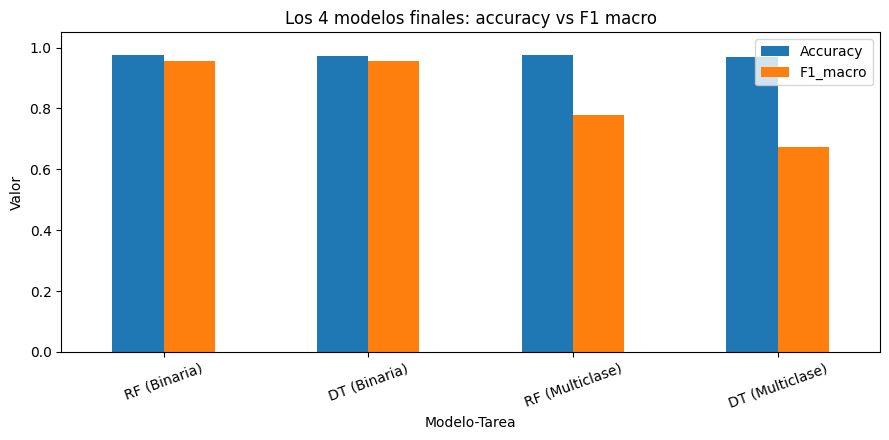

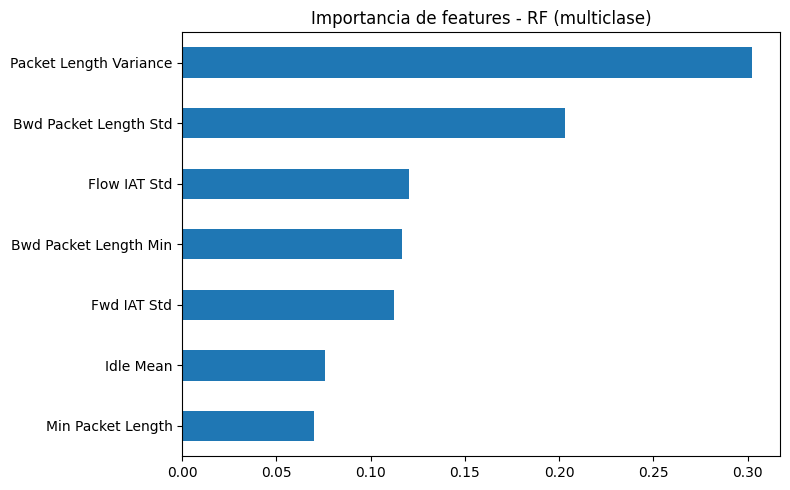

In [ ]:
# 5) Resumen final: 2 algoritmos x 2 tareas = 4 modelos
resumen = pd.concat([
    resultados_bin.loc[seleccionados].assign(Tarea='Binaria'),
    resultados_multi.assign(Tarea='Multiclase')]).reset_index()
resumen['Modelo-Tarea'] = resumen['Modelo'] + ' (' + resumen['Tarea'] + ')'
resumen = resumen.set_index('Modelo-Tarea')[['Accuracy', 'Precision', 'Recall', 'F1', 'F1_macro', 'fit_s', 'predict_s']]
display(resumen.round(4))

resumen[['Accuracy', 'F1_macro']].plot(kind='bar', figsize=(9, 4.5),
                                      title='Los 4 modelos finales: accuracy vs F1 macro')
plt.ylabel('Valor')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 6) Importancia de features (si alguno de los seleccionados es un modelo de arboles)
for nombre in seleccionados:
    m = modelos_multi[nombre]
    if hasattr(m, 'feature_importances_'):
        pd.Series(m.feature_importances_, index=FEATURES).sort_values().plot(
            kind='barh', figsize=(8, 5), title=f'Importancia de features - {nombre} (multiclase)')
        plt.tight_layout()
        plt.show()
        break

## Ablation study

Se quita **una pieza a la vez** del modelo completo (baseline) y se mide cuanto cambia el **F1 macro** en multiclase, mas el **recall por clase** (el promedio puede esconder que una clase rara se desploma).

Reglas para que sea valido:
- Todo se evalua en un split de validacion **dentro del train** (nunca el test), sobre una submuestra estratificada.
- Cada configuracion se repite con **3 semillas** (cambian el split interno y el modelo).
- Una diferencia solo cuenta como efecto real si supera la desviacion estandar entre semillas.

Experimentos: (1) grupos de features con Random Forest, (2) quitar `class_weight`, (3) volver a agregar las features redundantes eliminadas, (4) escalado en el SVM.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score
from sklearn.model_selection import train_test_split

SEEDS = [0, 1, 2]     # cada semilla cambia el split interno y el modelo
ABL_N = 60_000        # submuestra estratificada del TRAIN (el test no se toca)

idx_a = indices_estratificados(y_train_multi, ABL_N, 200)
A = train.iloc[idx_a]
ya = y_train_multi[idx_a]
clases_a = sorted(np.unique(ya))
inv_multi = {v: k for k, v in mapa_multi.items()}

# hiperparametros del RF ya buscados; class_weight se maneja aparte para poder ablacionarlo
base_params = dict(busqueda_res['RF'].best_params_)
cw_base = base_params.pop('class_weight', None) or 'balanced'

def cols_con(*claves):
    return [c for c in FEATURES if any(k.lower() in c.lower() for k in claves)]

grupos = {'IAT': cols_con('IAT'),
          'Length / Size': cols_con('Length', 'Size'),
          'Flags': cols_con('Flag'),
          'Idle / Active': cols_con('Idle', 'Active'),
          'Packets': cols_con('Packets'),
          'Bytes': cols_con('Bytes')}
grupos = {g: c for g, c in grupos.items() if c}
for g, c in grupos.items():
    print(f"{g}: {c}")

configs = {'baseline': dict(cols=FEATURES, cw=cw_base)}
for g, c in grupos.items():
    resto = [x for x in FEATURES if x not in c]
    if resto:
        configs[f'sin {g}'] = dict(cols=resto, cw=cw_base)
configs['sin class_weight'] = dict(cols=FEATURES, cw=None)
if a_eliminar:
    configs['+ redundantes'] = dict(cols=FEATURES + a_eliminar, cw=cw_base)

print(f"\n{len(configs)} configuraciones x {len(SEEDS)} semillas = {len(configs) * len(SEEDS)} entrenamientos")

IAT: ['Fwd IAT Std', 'Flow IAT Std']
Length / Size: ['Bwd Packet Length Std', 'Packet Length Variance', 'Min Packet Length', 'Bwd Packet Length Min']
Idle / Active: ['Idle Mean']

6 configuraciones x 3 semillas = 18 entrenamientos


In [ ]:
resultados_abl, recall_abl = [], {}
for nombre, cfg in configs.items():
    t0 = time.perf_counter()
    Xa = A[cfg['cols']].values
    f1s, recs = [], []
    for s in SEEDS:
        itr, iva = train_test_split(np.arange(len(A)), test_size=0.3, stratify=ya, random_state=s)
        m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=s,
                                   class_weight=cfg['cw'], **base_params).fit(Xa[itr], ya[itr])
        p = m.predict(Xa[iva])
        f1s.append(f1_score(ya[iva], p, average='macro'))
        recs.append(recall_score(ya[iva], p, labels=clases_a, average=None, zero_division=0))
    resultados_abl.append({'config': nombre, 'n_features': len(cfg['cols']),
                           'F1_macro': np.mean(f1s), 'std': np.std(f1s),
                           'tiempo_s': time.perf_counter() - t0})
    recall_abl[nombre] = np.mean(recs, axis=0)
    print(f"{nombre:22s} F1 macro = {np.mean(f1s):.4f} +- {np.std(f1s):.4f}")

tabla_abl = pd.DataFrame(resultados_abl).set_index('config')
base = tabla_abl.loc['baseline']
tabla_abl['delta'] = tabla_abl['F1_macro'] - base['F1_macro']
tabla_abl['efecto_real'] = tabla_abl['delta'].abs() > np.maximum(tabla_abl['std'], base['std'])
display(tabla_abl.round(4))

recall_df = pd.DataFrame(recall_abl, index=[inv_multi[c] for c in clases_a]).T
display(recall_df.round(3))

baseline               F1 macro = 0.6625 +- 0.0095
sin IAT                F1 macro = 0.6411 +- 0.0023
sin Length / Size      F1 macro = 0.5275 +- 0.0052
sin Idle / Active      F1 macro = 0.6650 +- 0.0043
sin class_weight       F1 macro = 0.8292 +- 0.0142
+ redundantes          F1 macro = 0.7137 +- 0.0024


,n_features,F1_macro,std,tiempo_s,delta,efecto_real
config,,,,,,
baseline,7,0.6625,0.0095,13.3560,0.0000,False
sin IAT,5,0.6411,0.0023,6.9682,-0.0214,True
sin Length / Size,3,0.5275,0.0052,12.5826,-0.1350,True
sin Idle / Active,6,0.6650,0.0043,13.0538,0.0025,False
sin class_weight,7,0.8292,0.0142,14.6928,0.1667,True
+ redundantes,8,0.7137,0.0024,19.6031,0.0512,True


,BENIGN,DoS,PortScan,DDoS,Brute Force,Web Attack,Bot,Raras
baseline,0.866,0.767,0.995,0.971,0.981,0.417,0.922,0.636
sin IAT,0.773,0.733,0.993,0.975,0.739,0.939,0.983,0.667
sin Length / Size,0.640,0.695,0.991,0.850,0.330,0.294,0.311,0.242
sin Idle / Active,0.866,0.754,0.994,0.957,0.985,0.411,0.922,0.697
sin class_weight,0.995,0.766,0.994,0.971,0.746,0.406,0.578,0.667
+ redundantes,0.946,0.966,0.995,0.974,0.879,0.556,0.761,0.697


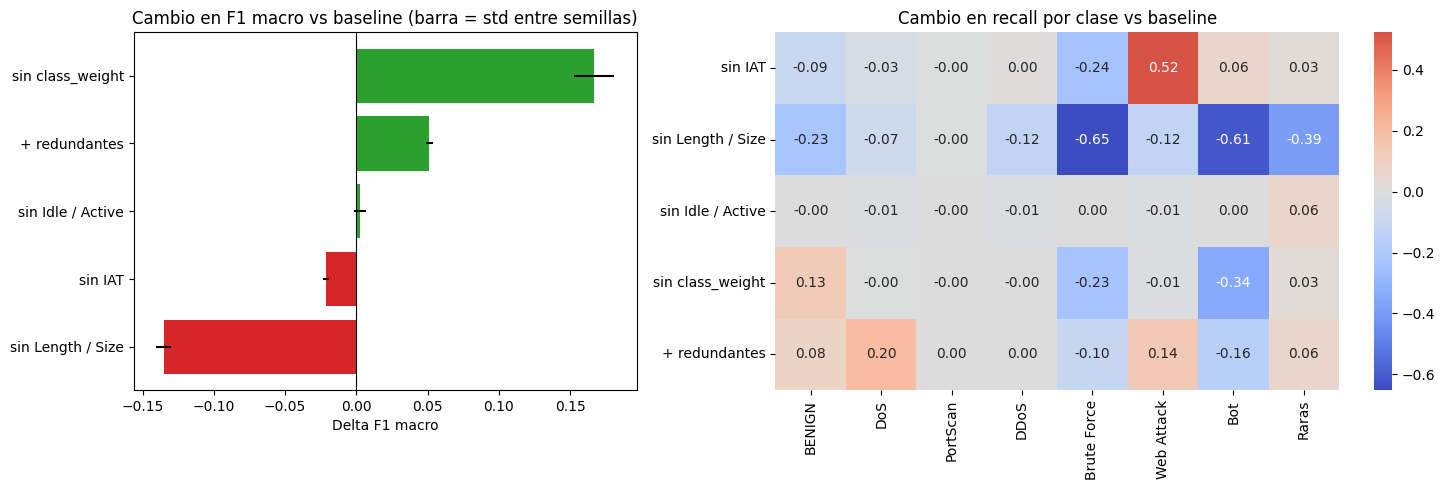

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

d = tabla_abl.drop('baseline')['delta'].sort_values()
axes[0].barh(d.index, d.values, xerr=tabla_abl.loc[d.index, 'std'].values,
             color=['tab:red' if v < 0 else 'tab:green' for v in d.values])
axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_title('Cambio en F1 macro vs baseline (barra = std entre semillas)')
axes[0].set_xlabel('Delta F1 macro')

sns.heatmap(recall_df.drop('baseline') - recall_df.loc['baseline'],
            annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Cambio en recall por clase vs baseline')
plt.tight_layout()
plt.show()

### Ablation del escalado (SVM)

El SVM con kernel RBF depende de distancias, asi que es donde el escalado deberia importar. Se compara el pipeline completo (`log con signo` + `StandardScaler`) contra versiones sin una o sin ambas piezas, con los mismos hiperparametros ya encontrados. Se usa una submuestra pequena porque el SVM es cuadratico en el numero de filas.

completo (log + StandardScaler)    F1 macro = 0.7716 +- 0.0225
sin StandardScaler                 F1 macro = 0.8508 +- 0.0070
sin log                            F1 macro = 0.5172 +- 0.0100
sin escalado (crudo)               F1 macro = 0.2706 +- 0.0042


,F1_macro,std,tiempo_s,delta
config,,,,
completo (log + StandardScaler),0.7716,0.0225,1.2542,0.0000
sin StandardScaler,0.8508,0.0070,3.8312,0.0792
sin log,0.5172,0.0100,2.0342,-0.2545
sin escalado (crudo),0.2706,0.0042,23.8972,-0.5011


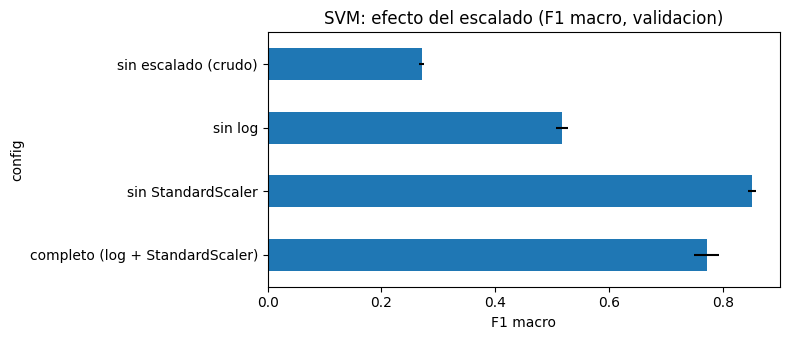

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SVM_ABL_N = 8_000
idx_b = indices_estratificados(y_train_multi, SVM_ABL_N, 100)
Xb, yb = X_train[idx_b], y_train_multi[idx_b]
sp = busqueda_res['SVM'].best_params_

def svm_pipe(log, escala, seed):
    pasos = []
    if log:
        pasos.append(FunctionTransformer(log_signed))
    if escala:
        pasos.append(StandardScaler())
    pasos.append(SVC(kernel='rbf', cache_size=500, random_state=seed, C=sp['svc__C'],
                     gamma=sp['svc__gamma'], class_weight=sp['svc__class_weight']))
    return make_pipeline(*pasos)

cfg_svm = {'completo (log + StandardScaler)': (True, True),
           'sin StandardScaler': (True, False),
           'sin log': (False, True),
           'sin escalado (crudo)': (False, False)}

filas_svm = []
for nombre, (log, escala) in cfg_svm.items():
    t0 = time.perf_counter()
    f1s = []
    for s in SEEDS:
        itr, iva = train_test_split(np.arange(len(Xb)), test_size=0.3, stratify=yb, random_state=s)
        m = svm_pipe(log, escala, s).fit(Xb[itr], yb[itr])
        f1s.append(f1_score(yb[iva], m.predict(Xb[iva]), average='macro'))
    filas_svm.append({'config': nombre, 'F1_macro': np.mean(f1s), 'std': np.std(f1s),
                      'tiempo_s': time.perf_counter() - t0})
    print(f"{nombre:34s} F1 macro = {np.mean(f1s):.4f} +- {np.std(f1s):.4f}")

tabla_svm = pd.DataFrame(filas_svm).set_index('config')
tabla_svm['delta'] = tabla_svm['F1_macro'] - tabla_svm.iloc[0]['F1_macro']
display(tabla_svm.round(4))

tabla_svm['F1_macro'].plot(kind='barh', xerr=tabla_svm['std'], figsize=(8, 3.5),
                           title='SVM: efecto del escalado (F1 macro, validacion)')
plt.xlabel('F1 macro')
plt.tight_layout()
plt.show()

### Conclusiones del ablation (completar tras correr)

- **Que grupo de features aporta mas?** (mirar la barra mas negativa del grafico y si `efecto_real` es True)
- **Alguna clase rara cae aunque el F1 macro casi no cambie?** (mirar el heatmap de recall)
- **Las features redundantes que se eliminaron importaban?** (fila `+ redundantes`: si el delta es menor que la std, la eliminacion se justifica)
- **Escalado:** que paso del pipeline del SVM pesa mas, el log o el StandardScaler?
- **Limitaciones:** submuestra de entrenamiento, 3 semillas, y los grupos de features se arman por nombre de columna.